# LM2 Lab — Limits and Derivatives

Companion notebook to **From Calculus to Kelly, LM2**. It rebuilds the module's exhibits and computational examples from verified data and solves the computational practice problems. Exhibits are named by title, because their numbers are assigned when the module is built.

| Part | Rebuilds |
|:--|:--|
| 1 | Limits: "Squeezing the slope of $e^x$ at zero" and the perpetuity limit ("From annuity to perpetuity") |
| 2 | "Difference quotients of a bond price" and "Duration of the 10-year bond as a derivative" |
| 3 | The TX account: near-month roll, "One TX contract, two accounts, two days", the leverage path and April 2025 |
| 4 | Elasticity of levered positions from 0050 data: 00631L and a margin-financed account |
| 5 | Finite differences: "Error of numerical derivatives…" and "Forward and central estimates…" |
| 6 | "Duration by bumping the yield"; symbolic checks with SymPy |
| 7 | Practice-problem solutions and an extension exercise |

**Notation** as in the module: $h$ and $u$ are generic functions, $\Delta x$ a step ($\Delta y$ for a yield), $f$ exposure ÷ equity, $N$ contracts with multiplier $m$, $F$ the futures price, $S$ the index and $E$ equity.

**Data.** `data/` holds a snapshot of FinMind data retrieved 2026-10-10: `TaiwanFuturesDaily` for TX (regular session; columns `date, contract_date, close, settlement_price, volume, open_interest`), `TaiwanStockPrice` closes for TAIEX, 0050 and 00631L (`date, close, spread`), and 0050 cash dividends from `TaiwanStockDividendResult`. Every close was checked against FinMind's own `spread` column. In the TX file the expiring contract shows `settlement_price = 0.0` on its expiry day, and thinly traded back months can show `close = 0.0`; the notebook therefore uses settlement prices and rolls one session before expiry. The folder is not in the repository (FinMind's licence forbids redistributing raw data): build it from the repository root with `python3 data/fetch_finmind.py` and `python3 data/make_lab_data.py` (needs `FINMIND_TOKEN`).

**Environment.** `uv pip install polars pyarrow numpy matplotlib sympy`.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import sympy as sp
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
EPS = np.finfo(float).eps
print(f"machine epsilon {EPS:.6e}, sqrt {math.sqrt(EPS):.2e}, cube root {EPS ** (1/3):.2e}")

machine epsilon 2.220446e-16, sqrt 1.49e-08, cube root 6.06e-06


## Part 1 — Limits

From Bernoulli's inequality, $1+x\le e^x\le 1/(1-x)$ for $x<1$ (eq. 2.1), so $(e^x-1)/x$ is squeezed between $1$ and $1/(1-x)$ and tends to 1 (eq. 2.2). Substituting $z=\ln(1+x)$ gives $\ln(1+x)/x\to1$ (eq. 2.3).

In [2]:
x = pl.col("x")
squeeze = (pl.DataFrame({"x": [0.1, 0.01, 0.001, -0.001, -0.01, -0.1]})
             .with_columns(((x.exp() - 1) / x).alias("(e^x-1)/x"),
                           pl.when(x > 0).then(pl.lit(1.0)).otherwise(1 / (1 - x)).alias("lower"),
                           pl.when(x > 0).then(1 / (1 - x)).otherwise(pl.lit(1.0)).alias("upper"),
                           (x.log1p() / x).alias("ln(1+x)/x")))
assert ((squeeze["lower"] <= squeeze["(e^x-1)/x"]) & (squeeze["(e^x-1)/x"] <= squeeze["upper"])).all()
squeeze   # exhibit "Squeezing the slope of e^x at zero"

x,(e^x-1)/x,lower,upper,ln(1+x)/x
f64,f64,f64,f64,f64
0.100000,1.051709,1.000000,1.111111,0.953102
0.010000,1.005017,1.000000,1.010101,0.995033
0.001000,1.000500,1.000000,1.001001,0.999500
-0.001000,0.999500,0.999001,1.000000,1.000500
-0.010000,0.995017,0.990099,1.000000,1.005034
-0.100000,0.951626,0.909091,1.000000,1.053605


In [3]:
# example "From annuity to perpetuity": a_{n,i} at i = 2%
ann = pl.DataFrame({"n": [10, 30, 100, 1000]}).with_columns(
    ((1 - pl.lit(1.02) ** (-pl.col("n").cast(pl.Float64))) / 0.02).alias("a_n"))
print(ann)
a100 = (1 - 1.02**-100) / 0.02
print(f"limit 1/i = {1/0.02:.4f};  missing after 100 years: 50 - a_100 = {50 - a100:.4f} = {(50 - a100) / 50:.2%} of 50;  "
      f"the gap shrinks by 1/1.02 = {1/1.02:.4f} a year")

shape: (4, 2)
┌──────┬───────────┐
│ n    ┆ a_n       │
│ ---  ┆ ---       │
│ i64  ┆ f64       │
╞══════╪═══════════╡
│ 10   ┆ 8.982585  │
│ 30   ┆ 22.396456 │
│ 100  ┆ 43.098352 │
│ 1000 ┆ 50.000000 │
└──────┴───────────┘
limit 1/i = 50.0000;  missing after 100 years: 50 - a_100 = 6.9016 = 13.80% of 50;  the gap shrinks by 1/1.02 = 0.9804 a year


## Part 2 — The derivative of a bond price

The 10-year bond pays a 2% annual coupon and is priced at a 2% yield (par). By the power and chain rules,
$P'(y)=-\sum_t t\,CF_t(1+y)^{-t-1}$, and $D_{\text{mod}}=-P'/P$, $D_{\text{Mac}}=(1+y)D_{\text{mod}}$ (eq. 2.6).

In [4]:
def bond_price(y, coupon=0.02, n=10, face=100.0):
    return sum(coupon * face / (1 + y) ** t for t in range(1, n + 1)) + face / (1 + y) ** n

def bond_dprice(y, coupon=0.02, n=10, face=100.0):
    return -sum(t * coupon * face / (1 + y) ** (t + 1) for t in range(1, n + 1)) - n * face / (1 + y) ** (n + 1)

y0 = 0.02
P0, dP = bond_price(y0), bond_dprice(y0)
rows = []
for dy_bp in (100, 10, 1, 0.1, 0.01):
    dy = dy_bp / 1e4
    fw = (bond_price(y0 + dy) - P0) / dy
    ce = (bond_price(y0 + dy) - bond_price(y0 - dy)) / (2 * dy)
    rows.append({"dy_bp": dy_bp, "forward": fw, "err_fwd": fw - dP, "central": ce, "err_cen": ce - dP})
print(f"P(2%) = {P0:.4f}   P'(2%) = {dP:.8f}")
pl.DataFrame(rows)   # exhibit "Difference quotients of a bond price at y0 = 2%"

P(2%) = 100.0000   P'(2%) = -898.25850062


dy_bp,forward,err_fwd,central,err_cen
f64,f64,f64,f64,f64
100.000000,-853.020284,45.238217,-900.075368,-1.816868
10.000000,-893.576823,4.681677,-898.276654,-0.018153
1.000000,-897.788705,0.469796,-898.258682,-0.000182
0.100000,-898.211505,0.046996,-898.258502,-0.000002
0.010000,-898.253801,0.004700,-898.258501,0.000000


In [5]:
# example "Duration of the 10-year bond as a derivative"
t = np.arange(1, 11)
cf = np.where(t == 10, 102.0, 2.0)
w = cf / 1.02**t / P0
Dmod = -dP / P0
print(f"Dmod = {Dmod:.6f}   Dmac = 1.02 x {Dmod:.6f} = {(1 + y0) * Dmod:.4f} = sum t*w = {(t * w).sum():.4f}   w_10 = {w[-1]:.4f}")
print(f"DV01 per 100 face {-dP * 1e-4:.5f};  per NT$100 million face {-dP * 1e-4 * 1e6:,.0f}")
print(f"annuity factor a_10 at 2% = {(1 - 1.02**-10) / 0.02:.4f}  (= Dmod of a par bond, Practice Problem 9)")
pl.DataFrame([{"dy_bp": d, "exact": bond_price(y0 + d / 1e4) / P0 - 1, "linear": -Dmod * d / 1e4}
              for d in (1, 10, 25, -25, 100, -100)]).with_columns((pl.col("exact") - pl.col("linear")).alias("error"))

Dmod = 8.982585   Dmac = 1.02 x 8.982585 = 9.1622 = sum t*w = 9.1622   w_10 = 0.8368
DV01 per 100 face 0.08983;  per NT$100 million face 89,826
annuity factor a_10 at 2% = 8.9826  (= Dmod of a par bond, Practice Problem 9)


dy_bp,exact,linear,error
i64,f64,f64,f64
1,-0.000898,-0.000898,0.000000
10,-0.008936,-0.008983,0.000047
25,-0.022166,-0.022456,0.000291
-25,0.022753,0.022456,0.000297
100,-0.085302,-0.089826,0.004524
-100,0.094713,0.089826,0.004887


## Part 3 — The TX account: the motivating case

**Roll rule.** The account holds the nearest contract whose expiry is after the *next* session, so it leaves the expiring contract at the close of the day before expiry. Closing the old and opening the new contract at their settlement prices is P&L-neutral under daily mark-to-market. Equity is $E_t=E_0+Nm\sum(F_t-F_{t-1})$ on the contract held, and leverage is $f=NmF/E$ (eq. 2.8).

In [6]:
M_TX = 200                                  # NT$ per index point (TAIFEX contract specification)
tx = pl.read_csv(DATA / "TX__2025-04-01__2025-10-31.csv")
ta = pl.read_csv(DATA / "TAIEX__2025-04-01__2025-10-31.csv").select("date", pl.col("close").alias("S")).sort("date")

expiry = (tx.filter(pl.col("settlement_price") == 0)
            .select("contract_date", pl.col("date").alias("expiry")))
days = ta.select("date").with_columns(pl.col("date").shift(-1).alias("next_date"))
days = days.with_columns(pl.coalesce("next_date", "date").alias("next_date"))      # last day: no roll
held = (tx.select("date", "contract_date")
          .join(days, on="date")
          .join(expiry, on="contract_date", how="left")
          .filter(pl.col("expiry").is_null() | (pl.col("expiry") > pl.col("next_date")))
          .group_by("date").agg(pl.col("contract_date").min().alias("held"))
          .sort("date"))
settle = tx.select("date", "contract_date", pl.col("settlement_price").alias("F"))

daily = (held.join(ta, on="date").sort("date")           # sort before shifting: never rely on row order after a join
           .with_columns(pl.col("date").shift(1).alias("prev_date"), pl.col("held").shift(1).alias("held_prev"),
                         pl.col("S").shift(1).alias("S_prev"))
           .join(settle.rename({"date": "prev_date", "contract_date": "held_prev", "F": "F0"}), on=["prev_date", "held_prev"], how="left")
           .join(settle.rename({"contract_date": "held_prev", "F": "F1"}), on=["date", "held_prev"], how="left")
           .join(settle.rename({"contract_date": "held", "F": "F_next"}), on=["date", "held"], how="left")
           .with_columns((pl.col("F1") / pl.col("F0") - 1).alias("RF"), (pl.col("S") / pl.col("S_prev") - 1).alias("RS"))
           .sort("date"))
print(sorted(expiry["expiry"].to_list()))
vol = tx.select("date", pl.col("contract_date").alias("held"), pl.col("volume").alias("vol_new"))
rolls = (daily.filter(pl.col("held") != pl.col("held_prev"))
              .join(vol, on=["date", "held"], how="left").sort("date")
              .select("date", "held_prev", "held", (pl.col("F1") - pl.col("F_next")).alias("old_minus_new"), "vol_new"))
print(rolls)
print(f"volume of the new contract on roll days: at least {rolls['vol_new'].min():,} contracts")
daily.drop_nulls("RF").select("date", "held_prev", pl.col("F0", "F1").cast(pl.Int64), "RF", "S_prev", "S", "RS").head(8)

['2025-04-16', '2025-05-21', '2025-06-18', '2025-07-16', '2025-08-20', '2025-09-17', '2025-10-15']
shape: (7, 5)
┌────────────┬───────────┬────────┬───────────────┬─────────┐
│ date       ┆ held_prev ┆ held   ┆ old_minus_new ┆ vol_new │
│ ---        ┆ ---       ┆ ---    ┆ ---           ┆ ---     │
│ str        ┆ i64       ┆ i64    ┆ f64           ┆ i64     │
╞════════════╪═══════════╪════════╪═══════════════╪═════════╡
│ 2025-04-15 ┆ 202504    ┆ 202505 ┆ 16.000000     ┆ 41339   │
│ 2025-05-20 ┆ 202505    ┆ 202506 ┆ 84.000000     ┆ 45424   │
│ 2025-06-17 ┆ 202506    ┆ 202507 ┆ 372.000000    ┆ 49873   │
│ 2025-07-15 ┆ 202507    ┆ 202508 ┆ 135.000000    ┆ 55753   │
│ 2025-08-19 ┆ 202508    ┆ 202509 ┆ 58.000000     ┆ 35485   │
│ 2025-09-16 ┆ 202509    ┆ 202510 ┆ -10.000000    ┆ 39771   │
│ 2025-10-14 ┆ 202510    ┆ 202511 ┆ -45.000000    ┆ 49859   │
└────────────┴───────────┴────────┴───────────────┴─────────┘
volume of the new contract on roll days: at least 35,485 contracts


date,held_prev,F0,F1,RF,S_prev,S,RS
str,i64,i64,i64,f64,f64,f64,f64
"""2025-04-02""",202504,21187,21296,0.005145,21280.170000,21298.220000,0.000848
"""2025-04-07""",202504,21296,19167,-0.099972,21298.220000,19232.350000,-0.096997
"""2025-04-08""",202504,19167,18169,-0.052069,19232.350000,18459.950000,-0.040161
"""2025-04-09""",202504,18169,17184,-0.054213,18459.950000,17391.760000,-0.057865
"""2025-04-10""",202504,17184,18902,0.099977,17391.760000,19000.030000,0.092473
"""2025-04-11""",202504,18902,19543,0.033912,19000.030000,19528.770000,0.027828
"""2025-04-14""",202504,19543,19497,-0.002354,19528.770000,19513.090000,-0.000803
"""2025-04-15""",202504,19497,19794,0.015233,19513.090000,19857.670000,0.017659


In [7]:
# exhibit "One TX contract, two accounts, two days": accounts with NT$600,000 (A) and NT$900,000 (B)
case = (daily.filter(pl.col("date").is_in(["2025-06-11", "2025-04-07"]))
          .with_columns((M_TX * (pl.col("F1") - pl.col("F0"))).alias("pnl"), (M_TX * pl.col("F0")).alias("notional"))
          .with_columns((pl.col("notional") / 600_000).alias("f_A"), (pl.col("notional") / 900_000).alias("f_B"),
                        (pl.col("pnl") / 600_000).alias("R_A"), (pl.col("pnl") / 900_000).alias("R_B"))
          .with_columns((pl.col("R_A") / pl.col("RS")).alias("R_A/RS"), (pl.col("R_B") / pl.col("RS")).alias("R_B/RS"),
                        (pl.col("RF") / pl.col("RS")).alias("eta_FS"))
          .select("date", "held_prev", "S_prev", "S", "RS", "F0", "F1", "RF", "pnl", "notional",
                  "f_A", "R_A", "f_B", "R_B", "R_A/RS", "R_B/RS", "eta_FS")
          .sort("date"))
for r in case.iter_rows(named=True):          # the exhibit's printed precision, and ratios recomputed from it
    RSp, RAp, RBp = round(100 * r["RS"], 3), round(100 * r["R_A"], 3), round(100 * r["R_B"], 3)
    print(f"{r['date']}: TAIEX {RSp:+.3f}%  TX {100 * r['RF']:+.3f}%  A {RAp:+.3f}%  B {RBp:+.3f}%  ratios {RAp / RSp:.1f}, {RBp / RSp:.1f}")
case

2025-04-07: TAIEX -9.700%  TX -9.997%  A -70.967%  B -47.311%  ratios 7.3, 4.9
2025-06-11: TAIEX +1.025%  TX +1.031%  A +7.600%  B +5.067%  ratios 7.4, 4.9


date,held_prev,S_prev,S,RS,F0,F1,RF,pnl,notional,f_A,R_A,f_B,R_B,R_A/RS,R_B/RS,eta_FS
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2025-04-07""",202504,21298.220000,19232.350000,-0.096997,21296.000000,19167.000000,-0.099972,-425800.000000,4259200.000000,7.098667,-0.709667,4.732444,-0.473111,7.316354,4.877570,1.030666
"""2025-06-11""",202506,22242.140000,22470.100000,0.010249,22116.000000,22344.000000,0.010309,45600.000000,4423200.000000,7.372000,0.076000,4.914667,0.050667,7.415348,4.943565,1.005880


In [8]:
# how typical were the case days? (a one-day case needs a multi-day figure)
d = daily.drop_nulls("RF")
RS, RF = d["RS"].to_numpy(), d["RF"].to_numpy()
rs0611 = case.filter(pl.col("date") == "2025-06-11")["RS"][0]
print(f"{d.height} daily returns; {int((np.abs(RS) > abs(rs0611)).sum())} moved more than 11 June ({rs0611:+.4%}); "
      f"median |RS| {np.median(np.abs(RS)):.3%}; largest fall {d.sort('RS')['date'][0]} ({RS.min():+.3%})")
# elasticity of the futures to the index over the window
near1 = d.filter(pl.col("RS").abs().is_between(0.009, 0.011)).with_columns((pl.col("RF") / pl.col("RS")).alias("ratio"))
print(f"median |RF| {np.median(np.abs(RF)):.3%};  OLS slope of RF on RS {np.polyfit(RS, RF, 1)[0]:.3f}; correlation {np.corrcoef(RS, RF)[0, 1]:.3f}")
print(f"{near1.height} days with 0.9% <= |RS| <= 1.1%: RF/RS from {near1['ratio'].min():.3f} to {near1['ratio'].max():.3f}")
n0611 = case.filter(pl.col("date") == "2025-06-11")["notional"][0]
MM = 350_000 * 538_000 / 701_000          # illustrative maintenance margin (TAIFEX's ratio applied to the illustrative 350,000)
print(f"leverage at an illustrative NT$350,000 initial margin on 11 June: {n0611 / 350_000:.2f};  illustrative maintenance margin {MM:,.0f}")

145 daily returns; 56 moved more than 11 June (+1.0249%); median |RS| 0.811%; largest fall 2025-04-07 (-9.700%)
median |RF| 0.820%;  OLS slope of RF on RS 1.008; correlation 0.978
14 days with 0.9% <= |RS| <= 1.1%: RF/RS from 0.753 to 1.459
leverage at an illustrative NT$350,000 initial margin on 11 June: 12.64;  illustrative maintenance margin 268,616


A: f 7.372 -> 2.894 (E 1,964,800);  B: f 4.915 -> 2.511
points gained 6,824 = 30.86% of F0;  A +227.47%, B +151.64%
TAIEX +26.936% (+5,991.21 points); f0 x TAIEX return = 198.57%
rolls after 10 June: [372.0, 135.0, 58.0, -10.0, -45.0] -> gains +565, costs -55, net +510
basis: 10 June -126.14, 31 October +196.65


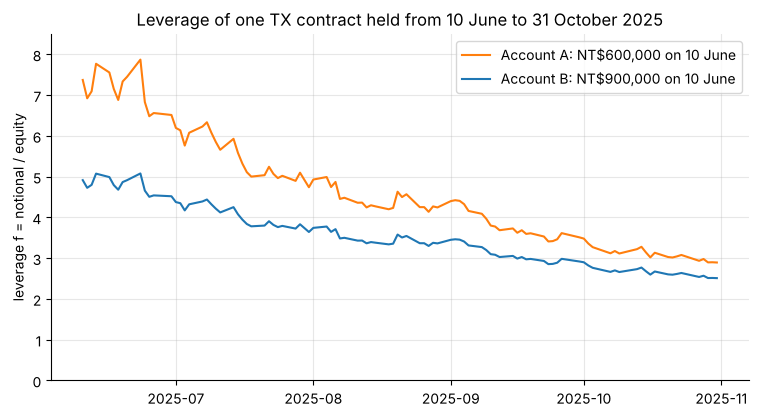

In [9]:
def account_path(start, E0, N=1):
    # equity and leverage of N contracts held from the close of `start`
    first = daily.filter(pl.col("date") == start)
    rest = daily.filter(pl.col("date") > start)
    pnl = (N * M_TX * (rest["F1"] - rest["F0"])).cum_sum()
    out = pl.DataFrame({"date": [start] + rest["date"].to_list(),
                        "F": [first["F_next"][0]] + rest["F_next"].to_list(),
                        "E": [float(E0)] + (E0 + pnl).to_list()})
    return out.with_columns(pl.when(pl.col("E") > 0).then(N * M_TX * pl.col("F") / pl.col("E")).otherwise(None).alias("f"))

pA, pB = account_path("2025-06-10", 600_000), account_path("2025-06-10", 900_000)
print(f"A: f {pA['f'][0]:.3f} -> {pA['f'][-1]:.3f} (E {pA['E'][-1]:,.0f});  B: f {pB['f'][0]:.3f} -> {pB['f'][-1]:.3f}")
pts = (pA["E"][-1] - 600_000) / M_TX
S0 = daily.filter(pl.col("date") == "2025-06-10")["S"][0]; S1 = daily["S"][-1]
print(f"points gained {pts:,.0f} = {pts / pA['F'][0]:.2%} of F0;  A {pA['E'][-1] / 600_000 - 1:+.2%}, B {pB['E'][-1] / 900_000 - 1:+.2%}")
print(f"TAIEX {S1 / S0 - 1:+.3%} ({S1 - S0:+,.2f} points); f0 x TAIEX return = {pA['f'][0] * (S1 / S0 - 1):.2%}")
r_after = rolls.filter(pl.col("date") > "2025-06-10")["old_minus_new"]
print(f"rolls after 10 June: {r_after.to_list()} -> gains {r_after.filter(r_after > 0).sum():+.0f}, costs {r_after.filter(r_after < 0).sum():+.0f}, net {r_after.sum():+.0f}")
print(f"basis: 10 June {pA['F'][0] - S0:+.2f}, 31 October {pA['F'][-1] - S1:+.2f}")

dates = pA["date"].str.to_date().to_list()
fig, ax = plt.subplots()
ax.plot(dates, pA["f"], label="Account A: NT$600,000 on 10 June", color="tab:orange")
ax.plot(dates, pB["f"], label="Account B: NT$900,000 on 10 June", color="tab:blue")
ax.set_ylim(0, 8.5); ax.set_ylabel("leverage f = notional / equity"); ax.set_title("Leverage of one TX contract held from 10 June to 31 October 2025")
ax.legend(); plt.show()

In [10]:
# exhibit "Leverage of a one-contract account in April 2025: exact and linear"
crash = account_path("2025-04-02", 900_000).head(5)
F0, f0 = crash["F"][0], crash["f"][0]
crash = crash.with_columns((pl.col("F") / F0 - 1).alias("move"),
                           (f0 - f0 * (f0 - 1) / F0 * (pl.col("F") - F0)).alias("f_linear"))
crashA = account_path("2025-04-02", 600_000).head(4)
print(f"zero-equity level B: {F0 - 900_000 / M_TX:,.0f};  A: {F0 - 600_000 / M_TX:,.0f}")
print(crashA)
for lab, p in (("A", crashA), ("B", crash)):
    below = p.filter((pl.col("date") > "2025-04-02") & (pl.col("E") < MM))
    print(f"{lab}: first session with equity below the illustrative maintenance margin: {below['date'][0]} (E {below['E'][0]:,.0f})")
F1 = F0 * 0.99; f1 = M_TX * F1 / (900_000 + M_TX * (F1 - F0))
print(f"hypothetical -1%: exact {f1:.4f}, linear {f0 - f0 * (f0 - 1) / F0 * (F1 - F0):.4f}")
crash

zero-equity level B: 16,796;  A: 18,296
shape: (4, 4)
┌────────────┬──────────────┬────────────────┬───────────┐
│ date       ┆ F            ┆ E              ┆ f         │
│ ---        ┆ ---          ┆ ---            ┆ ---       │
│ str        ┆ f64          ┆ f64            ┆ f64       │
╞════════════╪══════════════╪════════════════╪═══════════╡
│ 2025-04-02 ┆ 21296.000000 ┆ 600000.000000  ┆ 7.098667  │
│ 2025-04-07 ┆ 19167.000000 ┆ 174200.000000  ┆ 22.005741 │
│ 2025-04-08 ┆ 18169.000000 ┆ -25400.000000  ┆ null      │
│ 2025-04-09 ┆ 17184.000000 ┆ -222400.000000 ┆ null      │
└────────────┴──────────────┴────────────────┴───────────┘
A: first session with equity below the illustrative maintenance margin: 2025-04-07 (E 174,200)
B: first session with equity below the illustrative maintenance margin: 2025-04-09 (E 77,600)
hypothetical -1%: exact 4.9179, linear 4.9091


date,F,E,f,move,f_linear
str,f64,f64,f64,f64,f64
"""2025-04-02""",21296.000000,900000.000000,4.732444,0.000000,4.732444
"""2025-04-07""",19167.000000,474200.000000,8.083931,-0.099972,6.498305
"""2025-04-08""",18169.000000,274600.000000,13.233066,-0.146835,7.326079
"""2025-04-09""",17184.000000,77600.000000,44.288660,-0.193088,8.143069
"""2025-04-10""",18902.000000,421200.000000,8.975309,-0.112415,6.718105


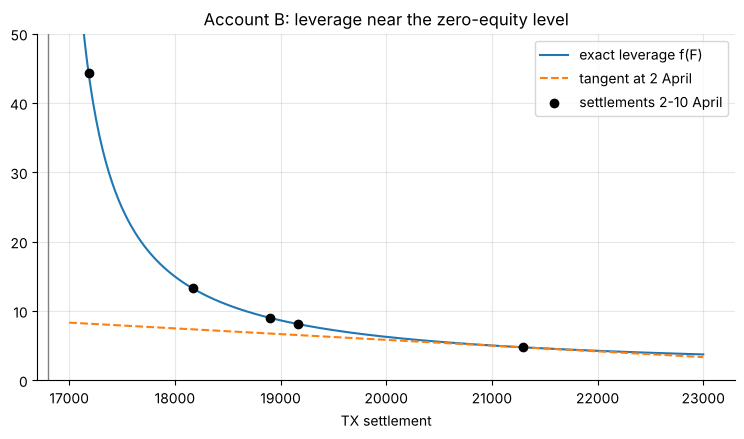

In [11]:
# the leverage function and its vertical asymptote (eqs. 2.8-2.9)
F = np.linspace(17_000, 23_000, 400)
E = 900_000 + M_TX * (F - F0)
lev = np.where(E > 0, M_TX * F / E, np.nan)
fig, ax = plt.subplots()
ax.plot(F, lev, label="exact leverage f(F)")
ax.plot(F, f0 - f0 * (f0 - 1) / F0 * (F - F0), "--", label="tangent at 2 April")
ax.scatter(crash["F"], crash["f"], color="black", zorder=3, label="settlements 2-10 April")
ax.axvline(F0 - 900_000 / M_TX, color="grey", lw=1); ax.set_ylim(0, 50); ax.set_xlabel("TX settlement")
ax.set_title("Account B: leverage near the zero-equity level"); ax.legend(); plt.show()

## Part 4 — Elasticity of levered positions from 0050 data

Total returns are rebuilt from the raw closes as in LM3: on an ex-dividend date $R_t=(P_t+D_t)/P_{t-1}-1$; on a split date the previous close is restated per new share, $R_t=P_t/(P_{t-1}/\text{ratio})-1$ (0050 4-for-1 on 2025-06-18; 00631L 22-for-1 on 2026-03-31).

In [12]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = df.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    assert set(gap["date"]) <= expected, set(gap["date"]) - expected
    sd, k = SPLITS[sym]
    dd = div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050" else pl.DataFrame(schema={"date": pl.Utf8, "D": pl.Float64})
    return (df.join(dd, on="date", how="left").sort("date")
              .with_columns(pl.col("D").fill_null(0.0), pl.when(pl.col("date") == sd).then(pl.lit(float(k))).otherwise(pl.lit(1.0)).alias("split"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("split").alias(f"S_{sym}")))

both = load_raw("0050").join(load_raw("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(
          ((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R_0050"),
          ((pl.col("P_00631L") + pl.col("D_00631L")) / (pl.col("P_00631L").shift(1) / pl.col("S_00631L")) - 1).alias("R_00631L"))
         .drop_nulls("R_0050").select("date", "P_0050", "R_0050", "R_00631L"))
print(ret.height, "daily returns", ret["date"][0], "->", ret["date"][-1])

2902 daily returns 2014-11-03 -> 2026-10-08


OLS slope 1.887, correlation 0.974
full calendar years 2015-2025: lowest 1.717 (2024), highest 1.984 (2021)
shape: (1, 5)
┌────────────┬────────────┬───────────┬───────────┬──────────┐
│ date       ┆ P_0050     ┆ R_0050    ┆ R_00631L  ┆ ratio    │
│ ---        ┆ ---        ┆ ---       ┆ ---       ┆ ---      │
│ str        ┆ f64        ┆ f64       ┆ f64       ┆ f64      │
╞════════════╪════════════╪═══════════╪═══════════╪══════════╡
│ 2025-04-07 ┆ 158.400000 ┆ -0.100000 ┆ -0.199950 ┆ 1.999501 │
└────────────┴────────────┴───────────┴───────────┴──────────┘


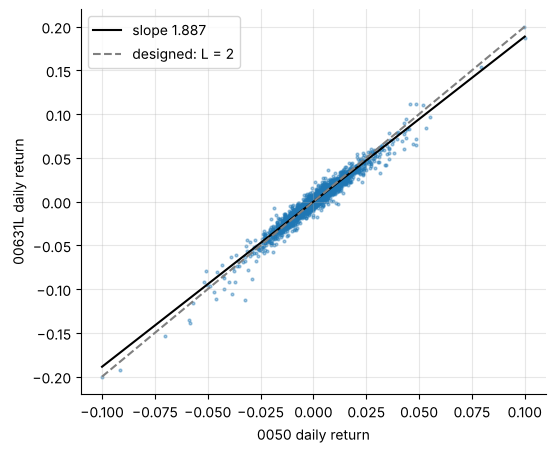

In [13]:
# example "The measured elasticity of 00631L to 0050"
R, RL = ret["R_0050"].to_numpy(), ret["R_00631L"].to_numpy()
b = np.polyfit(R, RL, 1)
print(f"OLS slope {b[0]:.3f}, correlation {np.corrcoef(R, RL)[0, 1]:.3f}")
by_year = (ret.with_columns(pl.col("date").str.slice(0, 4).cast(pl.Int32).alias("year"))
              .group_by("year")
              .agg((pl.cov("R_0050", "R_00631L") / pl.col("R_0050").var()).alias("slope"), pl.len().alias("n"))
              .sort("year"))
full = by_year.filter(pl.col("year").is_between(2015, 2025)).sort("slope")
print(f"full calendar years 2015-2025: lowest {full['slope'][0]:.3f} ({full['year'][0]}), highest {full['slope'][-1]:.3f} ({full['year'][-1]})")
print(ret.filter(pl.col("date") == "2025-04-07").with_columns((pl.col("R_00631L") / pl.col("R_0050")).alias("ratio")))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(R, RL, s=4, alpha=0.4); xx = np.linspace(R.min(), R.max(), 2)
ax.plot(xx, b[0] * xx + b[1], color="black", label=f"slope {b[0]:.3f}"); ax.plot(xx, 2 * xx, "--", color="grey", label="designed: L = 2")
ax.set_xlabel("0050 daily return"); ax.set_ylabel("00631L daily return"); ax.legend(); plt.show()

A **margin-financed 0050 position** shows the identity $\eta_{E,V}=V/E=f$ with real prices. Buy 0050 at the close of 2024-12-31 with half the money borrowed (interest ignored), hold the shares, and track equity. Each day the account's return is exactly $f_{t-1}$ times 0050's return, and $f$ drifts at the rate $1-f$.

In [14]:
start = ret.filter(pl.col("date") >= "2024-12-31")
V = ((1 + start["R_0050"]).cum_prod() / (1 + start["R_0050"][0])).to_numpy()   # position value per 1 at 2024-12-31
debt = 0.5; E = V - debt; f_m = V / E
acct = np.diff(E) / E[:-1]; asset = np.diff(V) / V[:-1]
print(f"leverage 2024-12-31: {f_m[0]:.3f};  end: {f_m[-1]:.3f};  max {np.nanmax(f_m):.3f} on {start['date'][int(np.argmax(f_m))]}")
print(f"max |account return - f_prev * asset return| = {np.max(np.abs(acct - f_m[:-1] * asset)):.2e}")

leverage 2024-12-31: 2.000;  end: 1.257;  max 2.944 on 2025-04-09
max |account return - f_prev * asset return| = 2.78e-17


## Part 5 — Finite differences: truncation versus rounding

Forward differences have truncation error $O(\Delta x)$ and central differences $O(\Delta x^2)$ (eq. 2.11); rounding adds roughly $\varepsilon_{\mathrm m}|h|/\Delta x$. The scan below rebuilds the exhibits "Error of numerical derivatives of the bond price versus step size" and "Forward and central estimates of $P'(2\%)$ at selected steps".

P' = -898.25850062   P'' = 9399.5462   P''' = -108918.1833   convexity P''/P = 93.9955
best forward: (-8.25, 2.4065728923624497e-08, 6.880771852369237e-09)  best central: (-5.75, 9.30412916696181e-06, 6.067459419072373e-12)
model optimum: forward dy* = 3.07e-09, central dy* = 8.49e-07


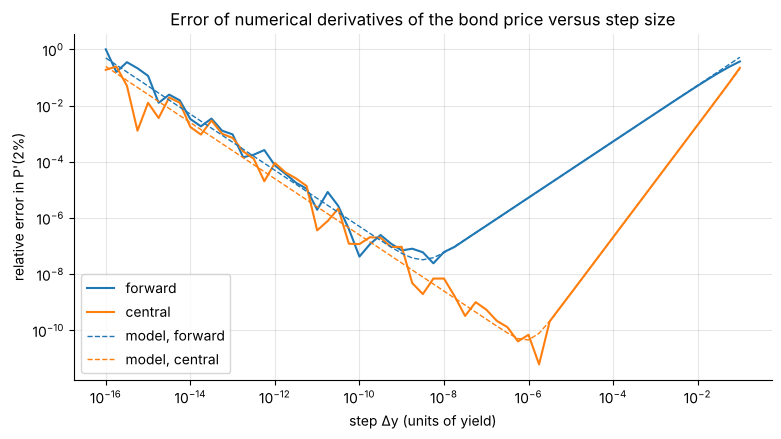

In [15]:
def fwd(fun, x, dx): return (fun(x + dx) - fun(x)) / dx
def cen(fun, x, dx): return (fun(x + dx) - fun(x - dx)) / (2 * dx)

y_ = sp.Symbol("y")
Ps = sum(sp.Integer(2) / (1 + y_) ** k for k in range(1, 11)) + 100 / (1 + y_) ** 10
d1, d2, d3 = (float(sp.diff(Ps, y_, k).subs(y_, sp.Rational(1, 50))) for k in (1, 2, 3))
print(f"P' = {d1:.8f}   P'' = {d2:.4f}   P''' = {d3:.4f}   convexity P''/P = {d2 / 100:.4f}")

ks = np.round(np.arange(-16, -0.99, 0.25), 2)
scan = pl.DataFrame({"log10_dy": ks}).with_columns(
    pl.Series("rel_fwd", [abs(fwd(bond_price, y0, 10.0**k) - d1) / abs(d1) for k in ks]),
    pl.Series("rel_cen", [abs(cen(bond_price, y0, 10.0**k) - d1) / abs(d1) for k in ks]))
best_f = scan.filter(pl.col("rel_fwd") > 0).sort("rel_fwd").head(1)
best_c = scan.filter(pl.col("rel_cen") > 0).sort("rel_cen").head(1)
print("best forward:", best_f.row(0), " best central:", best_c.row(0))
print(f"model optimum: forward dy* = {2 * math.sqrt(EPS * P0 / abs(d2)):.2e}, central dy* = {(3 * EPS * P0 / abs(d3)) ** (1/3):.2e}")

dys = 10.0 ** ks
fig, ax = plt.subplots()
ax.loglog(dys, scan["rel_fwd"], label="forward"); ax.loglog(dys, scan["rel_cen"], label="central")
ax.loglog(dys, (abs(d2) / 2 * dys + 2 * EPS * P0 / dys) / abs(d1), "--", color="tab:blue", lw=1, label="model, forward")
ax.loglog(dys, (abs(d3) / 6 * dys**2 + EPS * P0 / dys) / abs(d1), "--", color="tab:orange", lw=1, label="model, central")
ax.set_xlabel("step Δy (units of yield)"); ax.set_ylabel("relative error in P'(2%)")
ax.set_title("Error of numerical derivatives of the bond price versus step size"); ax.legend(); plt.show()

In [16]:
# exhibit "Forward and central estimates of P'(2%) at selected steps" (relative errors in scientific notation)
pl.DataFrame([{"dy": f"1e-{k:02d}", "forward": f"{fwd(bond_price, y0, 10.0**-k):.8f}",
               "rel_fwd": f"{(fwd(bond_price, y0, 10.0**-k) - d1) / abs(d1):+.1e}",
               "central": f"{cen(bond_price, y0, 10.0**-k):.8f}",
               "rel_cen": f"{(cen(bond_price, y0, 10.0**-k) - d1) / abs(d1):+.1e}"}
              for k in (2, 4, 6, 8, 10, 12)])

dy,forward,rel_fwd,central,rel_cen
str,str,str,str,str
"""1e-02""","""-853.02028368""","""+5.0e-02""","""-900.07536837""","""-2.0e-03"""
"""1e-04""","""-897.78870479""","""+5.2e-04""","""-898.25868215""","""-2.0e-07"""
"""1e-06""","""-898.25380077""","""+5.2e-06""","""-898.25850056""","""+6.9e-11"""
"""1e-08""","""-898.25844611""","""+6.1e-08""","""-898.25849443""","""+6.9e-09"""
"""1e-10""","""-898.25846317""","""+4.2e-08""","""-898.25860528""","""-1.2e-07"""
"""1e-12""","""-898.32496997""","""-7.4e-05""","""-898.33918082""","""-9.0e-05"""


In [17]:
# model components of the forward error near the plateau (Solution 16)
for dy in (1e-8, 1e-9, 1e-10):
    print(f"dy={dy:.0e}: truncation {abs(d2) / 2 * dy / abs(d1):.1e}, rounding {2 * EPS * P0 / dy / abs(d1):.1e}, "
          f"observed {abs(fwd(bond_price, y0, dy) - d1) / abs(d1):.1e}")
print(f"crossover of the two terms: {2 * math.sqrt(EPS * P0 / abs(d2)):.1e}")
# orders of convergence: error/dx -> h''/2 (forward) and error/dx^2 -> h'''/6 (central) for h = e^x at 0
for dx in (0.1, 0.05, 0.025):
    ef, ec = fwd(math.exp, 0.0, dx) - 1, cen(math.exp, 0.0, dx) - 1
    print(f"dx={dx:<6} forward err/dx {ef / dx:.4f}   central err/dx^2 {ec / dx**2:.5f}")
# a kink: the call payoff max(x-1, 0) at the strike
call = lambda x: max(x - 1.0, 0.0)
for dx in (0.1, 0.001):
    print(f"kink dx={dx}: forward {fwd(call, 1.0, dx):.3f}  backward {(call(1.0) - call(1.0 - dx)) / dx:.3f}  central {cen(call, 1.0, dx):.3f}")

dy=1e-08: truncation 5.2e-08, rounding 4.9e-09, observed 6.1e-08
dy=1e-09: truncation 5.2e-09, rounding 4.9e-08, observed 5.3e-08
dy=1e-10: truncation 5.2e-10, rounding 4.9e-07, observed 4.2e-08
crossover of the two terms: 3.1e-09
dx=0.1    forward err/dx 0.5171   central err/dx^2 0.16675
dx=0.05   forward err/dx 0.5084   central err/dx^2 0.16669
dx=0.025  forward err/dx 0.5042   central err/dx^2 0.16667
kink dx=0.1: forward 1.000  backward 0.000  central 0.500
kink dx=0.001: forward 1.000  backward 0.000  central 0.500


## Part 6 — Duration by bumping yields

A desk prices with code and bumps the yield. The central bump is the effective duration $(PV_--PV_+)/(2\,\Delta\text{Curve}\,PV_0)$, here with the bond's own yield as the curve.

In [18]:
for bump_bp in (100, 25, 1, 0.01):
    dy = bump_bp / 1e4
    Df = -fwd(bond_price, y0, dy) / P0; Dc = -cen(bond_price, y0, dy) / P0
    print(f"bump {bump_bp:>6} bp: forward {Df:.6f} (err {Df - Dmod:+.2e})   central {Dc:.6f} (err {Dc - Dmod:+.2e}, relative {abs(Dc - Dmod) / Dmod:.1e})")
print(f"exact D_mod {Dmod:.6f};  SymPy: {sp.N((-sp.diff(Ps, y_) / Ps).subs(y_, sp.Rational(1, 50)), 8)}")
F_, E0_, F0_, N_, m_ = sp.symbols("F E_0 F_0 N m", positive=True)
f_ = N_ * m_ * F_ / (E0_ + N_ * m_ * (F_ - F0_))
print("check f'(F) = -f(f-1)/F:", sp.simplify(sp.diff(f_, F_) + f_ * (f_ - 1) / F_) == 0)

bump    100 bp: forward 8.530203 (err -4.52e-01)   central 9.000754 (err +1.82e-02, relative 2.0e-03)
bump     25 bp: forward 8.866216 (err -1.16e-01)   central 8.983720 (err +1.13e-03, relative 1.3e-04)
bump      1 bp: forward 8.977887 (err -4.70e-03)   central 8.982587 (err +1.82e-06, relative 2.0e-07)
bump   0.01 bp: forward 8.982538 (err -4.70e-05)   central 8.982585 (err -6.16e-10, relative 6.9e-11)
exact D_mod 8.982585;  SymPy: 8.9825850
check f'(F) = -f(f-1)/F: True


## Part 7 — Practice-problem solutions (computational)

In [19]:
print("PP3 ", f"{1 / (2 * math.sqrt(4)):.4f}")
print("PP5 ", 200 - 3 * 50 + 7 * 10, "NT$/pt;", (200 - 3 * 50 + 7 * 10) * -250)
print("PP6 ", f"f = {2 * 50 * 25_000 / 500_000:.1f}; return {2 * 50 * 25_000 / 500_000 * 1.2:.1f}%")
print("PP7 ", f"+2%: exact {8 * 1.02 / 1.16:.4f}, linear {8 * (1 - 7 * 0.02):.4f};  -2%: exact {8 * 0.98 / 0.84:.4f}, linear {8 * (1 + 7 * 0.02):.4f}")
print("PP8 ", f"annual Dmod {5 / 1.02:.4f}; continuous {5:.4f}")
y_par, n_par = 0.02, 10
print("PP9 ", f"a_(n,y0) = {(1 - (1 + y_par)**-n_par) / y_par:.4f};  -P'/P = {-bond_dprice(y_par) / bond_price(y_par):.4f}")
print("PP10", f"exact {1.08 * 0.95 - 1:+.4%}; first order {0.08 - 0.05:+.2%}; cross {0.08 * -0.05:+.4%}")
print("PP11", f"forward {fwd(math.log, 2, 0.01):.6f} (err {fwd(math.log, 2, 0.01) - 0.5:+.7f});  central {cen(math.log, 2, 0.01):.7f} (err {cen(math.log, 2, 0.01) - 0.5:+.3e})")
g1 = lambda f: 0.01 / (1 + 0.02 * f) - 0.005 / (1 - 0.01 * f)          # g'(f)
print("PP13", {f: round(g1(f), 6) for f in (0, 10, 25, 40)})
CY = 2 / P0
print("PP14", f"CY' = {CY * Dmod:.5f}; x 10 bp = {CY * Dmod * 0.001 * 1e4:.2f} bp; exact {(2 / bond_price(0.021) - CY) * 1e4:.2f} bp")
S, r_f, q, tau = 22_470.10, 0.016, 0.030, 0.25
Ffv = S * math.exp((r_f - q) * tau)
print("PP15", f"F = {Ffv:.1f}; dF/dS = {math.exp((r_f - q) * tau):.6f}; dF/dq x 0.001 = {-tau * Ffv * 0.001:.2f} points")
print("PP16 decade-grid minima (k, relative error) for dy = 1e-k:",
      min(((k, abs(fwd(bond_price, y0, 10.0**-k) - d1) / abs(d1)) for k in range(1, 13)), key=lambda z: z[1]),
      min(((k, abs(cen(bond_price, y0, 10.0**-k) - d1) / abs(d1)) for k in range(1, 13)), key=lambda z: z[1]))

PP3  0.2500
PP5  120 NT$/pt; -30000
PP6  f = 5.0; return 6.0%
PP7  +2%: exact 7.0345, linear 6.8800;  -2%: exact 9.3333, linear 9.1200
PP8  annual Dmod 4.9020; continuous 5.0000
PP9  a_(n,y0) = 8.9826;  -P'/P = 8.9826
PP10 exact +2.6000%; first order +3.00%; cross -0.4000%
PP11 forward 0.498754 (err -0.0012458);  central 0.5000042 (err +4.167e-06)
PP13 {0: 0.005, 10: 0.002778, 25: 0.0, 40: -0.002778}
PP14 CY' = 0.17965; x 10 bp = 1.80 bp; exact 1.80 bp
PP15 F = 22391.6; dF/dS = 0.996506; dF/dq x 0.001 = -5.60 points
PP16 decade-grid minima (k, relative error) for dy = 1e-k: (10, 4.1700146783499127e-08) (6, 6.86296232755459e-11)


### Extension: Richardson extrapolation

The central difference has error $\kappa_2\Delta x^2+\kappa_4\Delta x^4+\cdots$ for constants $\kappa_2$, $\kappa_4$ (the even powers follow from Taylor's theorem in LM3). Combining two steps cancels the $\Delta x^2$ term:
$$Q_R(\Delta x)=\frac{4Q_c(\Delta x/2)-Q_c(\Delta x)}{3}=h'(x)+O(\Delta x^4).$$
Implement $Q_R$ for the bond, scan the step as in Part 5, and answer: what is the best step now, and how small is the smallest error? Explain the new optimum with the same truncation-versus-rounding argument ($\operatorname{err}(\Delta x)\approx\kappa\,\Delta x^4+\varepsilon_{\mathrm m}|h|/\Delta x$, so $\Delta x^*\propto\varepsilon_{\mathrm m}^{1/5}$). A starting point:

In [20]:
def richardson(fun, x, dx):
    return (4 * cen(fun, x, dx / 2) - cen(fun, x, dx)) / 3

for k in (2, 3, 4):
    print(f"dy=1e-{k}: central rel err {abs(cen(bond_price, y0, 10.0**-k) - d1) / abs(d1):.1e}   Richardson {abs(richardson(bond_price, y0, 10.0**-k) - d1) / abs(d1):.1e}")

dy=1e-2: central rel err 2.0e-03   Richardson 4.4e-07
dy=1e-3: central rel err 2.0e-05   Richardson 4.4e-11
dy=1e-4: central rel err 2.0e-07   Richardson 2.6e-13
